In [1]:
import os
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import pickle

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, zscore

from sklearn.base import BaseEstimator
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index, median_survival_times
from sksurv.metrics import concordance_index_censored, cumulative_dynamic_auc

In [2]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sns.set_style("whitegrid")
np.random.seed(42)

kmf = KaplanMeierFitter()

# Data Cleaning and Pre-processing

In [3]:
clinical_693 = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\mRNAseq_693\Clinical\CGGA.mRNAseq_693_clinical.20200506.txt\CGGA.mRNAseq_693_clinical.20200506.txt",
    sep="\t",
    low_memory=False
)

expression_693 = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\mRNAseq_693\Gene Expression\CGGA.mRNAseq_693.RSEM-genes.20200506.txt\CGGA.mRNAseq_693.RSEM-genes.20200506.txt",
    sep="\t",
    low_memory=False
)

mutation_286 = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\WEseq_286\Somatic Mutation\CGGA.WEseq_286.20200506.txt\CGGA.WEseq_286.20200506.txt",
    sep="\t",
    low_memory=False
)

In [4]:
expr_ids = set(expression_693.columns[1:])     
mut_ids = set(mutation_286.columns[1:])         

overlap = expr_ids & mut_ids

print("Expression patients:", len(expr_ids))
print("Mutation patients:", len(mut_ids))
print("Overlap:", len(overlap))

Expression patients: 693
Mutation patients: 286
Overlap: 185


## Clinical

In [5]:
clinical_693.head(2)

,CGGA_ID,PRS_type,Histology,Grade,Gender,Age,OS,Censor (alive=0; dead=1),Radio_status (treated=1;un-treated=0),Chemo_status (TMZ treated=1;un-treated=0),IDH_mutation_status,1p19q_codeletion_status,MGMTp_methylation_status
0,CGGA_1002,Primary,AA,WHO III,Female,43.0,305.0,1.0,1.0,1.0,Wildtype,Non-codel,methylated
1,CGGA_1003,Primary,O,WHO II,Female,47.0,3817.0,0.0,0.0,1.0,Mutant,Codel,un-methylated


In [6]:
PRIMARY_ONLY = True  # True: primary tumours only; False: primary and recurrent

clinical_693 = clinical_693[
    clinical_693["Grade"].str.strip().isin(["WHO II", "WHO III"])
].copy()

if PRIMARY_ONLY:
    clinical_693 = clinical_693[clinical_693["PRS_type"].str.strip() == "Primary"].copy()

print(f"Grade II/III tumours kept: {len(clinical_693)} ({'primary only' if PRIMARY_ONLY else 'primary and recurrent'})")

Grade II/III tumours kept: 282 (primary only)


In [7]:
clinical_693.shape

(282, 13)

### Feature Set

In [8]:
clinical_final = clinical_693[
    [
        "CGGA_ID",
        "Censor (alive=0; dead=1)",
        "OS",
        "Gender",
        "Age"
    ]
].copy()

clinical_final = clinical_final.rename(columns={
    "CGGA_ID": "patient_id",
    "Censor (alive=0; dead=1)": "event",
    "OS": "time",
    "Gender": "gender",
    "Age": "age"
})

In [9]:
clinical_final["gender"] = (
    clinical_final["gender"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "female": 1,
        "male": 0
    })
)
assert clinical_final["gender"].notnull().all()

clinical_final["event"] = pd.to_numeric(clinical_final["event"], errors="coerce")

In [10]:
clinical_final["time"] = pd.to_numeric(clinical_final["time"], errors="coerce")
clinical_final["age"] = pd.to_numeric(clinical_final["age"], errors="coerce")

clinical_final = clinical_final.dropna(
    subset=["event", "time", "age"]
).set_index("patient_id")

assert clinical_final["time"].notnull().all()
assert clinical_final["event"].isin([0, 1]).all()

clinical_final = clinical_final[~clinical_final.index.duplicated(keep="first")]

clinical_final = clinical_final[["event", "time", "gender", "age"]]

In [11]:
clinical_final = clinical_final.astype({
    "event": int,
    "time": float,
    "gender": int,
    "age": float,
})

clinical_final.head()

,event,time,gender,age
patient_id,,,,
CGGA_1002,1,305.0,1,43.0
CGGA_1003,0,3817.0,1,47.0
CGGA_1010,1,246.0,0,45.0
CGGA_1014,1,263.0,0,42.0
CGGA_103,1,1188.0,0,56.0


In [12]:
n_before = len(clinical_final)
clinical_final = clinical_final[~(clinical_final["age"] < 18)]
print(f"Patients under 18 excluded: {n_before - len(clinical_final)}")

Patients under 18 excluded: 5


## Somatic Mutation

In [13]:
mutation_286 = mutation_286.rename(columns={"Unnamed: 0": "Gene"})

### Feature Set

In [14]:
selected_mutations_df = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\Biological Feature Selection\Final Feature Sets\somatic_mutation_features.tsv",
    sep="\t"
)

In [15]:
mutation_genes = selected_mutations_df["Gene"].tolist()

In [16]:
mutation_final = mutation_286[
    mutation_286["Gene"].isin(mutation_genes)
].copy()

mutation_final = mutation_final.set_index("Gene").T

mutation_duplicates = mutation_final.index[mutation_final.index.duplicated()].unique()
print(f"Duplicates: {len(mutation_duplicates)}")
mutation_final = mutation_final[~mutation_final.index.duplicated(keep="first")]

mutation_final = mutation_final.reindex(columns=mutation_genes, fill_value=np.nan)
mutation_final = mutation_final.rename_axis(None, axis=1)
mutation_final = mutation_final.add_suffix("_mut")
mutation_final = mutation_final.notna().astype(int)
mutation_final.index.name = "patient_id"

mutation_final.head(5)

Duplicates: 0


,ATRX_mut,CIC_mut,EGFR_mut,FUBP1_mut,IDH1_mut,NF1_mut,NOTCH1_mut,PIK3CA_mut,PTEN_mut,TP53_mut
patient_id,,,,,,,,,,
CGGA_528,0,0,0,0,0,0,0,0,0,0
CGGA_579,0,0,0,0,0,0,0,0,0,0
CGGA_653,0,1,0,0,1,0,0,0,0,0
CGGA_715,0,1,0,0,1,0,0,0,0,0
CGGA_723,0,1,0,0,1,0,0,0,0,0


## Gene Expression

In [17]:
expression_693 = expression_693.rename(columns={"Gene_Name": "Gene"})

In [18]:
expression_fpkm = expression_693.set_index("Gene").apply(pd.to_numeric, errors="coerce")
expression_tpm = expression_fpkm.div(expression_fpkm.sum(axis=0), axis=1) * 1e6
expression_693 = expression_tpm.reset_index()

### Feature Set

In [19]:
selected_expression_df = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\Biological Feature Selection\Final Feature Sets\gene_expr_features.tsv",
    sep="\t"
)

In [20]:
expression_genes = selected_expression_df["Gene"].tolist()

In [21]:
expression_genes = [gene for gene in expression_genes if gene != "HN1"]

In [22]:
available_genes = [gene for gene in expression_genes if gene in expression_693["Gene"].values]
expression_original = expression_693[expression_693["Gene"].isin(available_genes)].copy()

missing_genes = [gene for gene in expression_genes if gene not in expression_693["Gene"].values]

print("Missing genes:")
print(missing_genes)

expression_original = expression_original.set_index("Gene")
expression_original = expression_original.T
expression_original = expression_original.apply(pd.to_numeric, errors="coerce")

expression_duplicates = expression_original.index[expression_original.index.duplicated()].unique()
print(f"Duplicates: {len(expression_duplicates)}")
expression_original = expression_original.groupby(expression_original.index).median()

expression_original = expression_original.add_suffix("_exp")
expression_original = expression_original.rename_axis(None, axis=1)

expression_final = np.log1p(expression_original)

expression_final.index.name = "patient_id"
expression_final = expression_final[[f"{gene}_exp" for gene in available_genes]]

expr_cols = expression_final.columns

expression_final.head()

Missing genes:
['EZHIP']
Duplicates: 0


,ACVR1_exp,ALDOB_exp,ALDOC_exp,ALK_exp,ARNTL_exp,ARPC1B_exp,ATRX_exp,AURKB_exp,BRAF_exp,CDC45_exp,...,RPA2_exp,S100A11_exp,SHC1_exp,SOX9_exp,SPP1_exp,TP53_exp,TSC1_exp,TSC2_exp,VAV3_exp,ZYX_exp
patient_id,,,,,,,,,,,,,,,,,,,,,
CGGA_1002,1.719713,0.282558,6.388967,0.366816,2.463014,4.119216,1.762642,2.607074,1.865247,2.149423,...,3.364443,4.659132,3.079412,3.179840,5.819667,2.336095,2.554094,4.613583,0.772946,4.776488
CGGA_1003,1.423363,0.194982,6.161994,0.279852,2.108002,2.787873,2.984627,1.476165,1.644530,1.432749,...,2.489733,3.337408,3.481565,3.784172,3.451623,3.410790,2.573752,4.681759,0.153888,3.974572
CGGA_1010,0.043996,0.004028,0.980340,0.036241,0.090362,0.273723,0.093518,0.337846,0.334962,0.144702,...,0.132655,0.073895,0.214554,0.461500,0.240277,0.670649,0.137692,0.570881,0.006323,0.249306
CGGA_1012,2.689636,0.325889,6.148992,0.293588,2.394413,4.984596,1.258663,2.851462,1.753926,1.588550,...,3.707406,5.423372,3.688866,3.747646,7.175846,3.377970,2.325839,4.203718,0.533259,4.707424
CGGA_1014,2.099267,0.055271,6.156602,0.764492,2.593529,3.867555,1.591210,3.125710,1.729365,2.189756,...,3.745634,5.049935,3.337210,3.928851,4.095441,2.959425,2.225988,4.807334,1.213130,5.300853


## Final Feature Set

In [23]:
merged_df = pd.concat([clinical_final, mutation_final, expression_final], axis=1, join='inner')

In [24]:
print("Clinical:", clinical_final.shape)
print("Mutation:", mutation_final.shape)
print("Expression:", expression_final.shape)
print("Merged:", merged_df.shape)

Clinical: (265, 4)
Mutation: (286, 10)
Expression: (693, 68)
Merged: (69, 82)


In [25]:
print(f"Patients in clinical: {len(clinical_final)}")
print(f"Patients after adding mutation: {len(clinical_final.index.intersection(mutation_final.index))}")
print(f"Final merged: {len(merged_df)}")

Patients in clinical: 265
Patients after adding mutation: 69
Final merged: 69


In [26]:
merged_df.head()

,event,time,gender,age,ATRX_mut,CIC_mut,EGFR_mut,FUBP1_mut,IDH1_mut,NF1_mut,...,RPA2_exp,S100A11_exp,SHC1_exp,SOX9_exp,SPP1_exp,TP53_exp,TSC1_exp,TSC2_exp,VAV3_exp,ZYX_exp
patient_id,,,,,,,,,,,,,,,,,,,,,
CGGA_1226,1,670.0,1,33.0,0,0,0,0,0,0,...,3.473220,4.647103,3.136959,4.038378,5.703306,2.243095,2.323042,3.968791,0.443808,4.070061
CGGA_1232,1,2067.0,0,39.0,1,0,0,0,0,0,...,3.252192,4.908902,3.087515,4.052260,6.327017,3.515677,2.344027,5.232014,0.157962,5.227800
CGGA_1303,0,2861.0,1,45.0,0,0,0,0,1,0,...,0.163201,0.171171,0.411814,0.446931,0.242869,0.454570,0.319771,0.986546,0.015297,0.387117
CGGA_1305,1,2702.0,0,43.0,1,0,0,0,0,0,...,3.179011,4.713975,2.099121,3.487693,4.820447,3.244124,1.859380,4.890201,0.042983,4.501272
CGGA_1317,0,2864.0,0,45.0,0,0,0,0,1,0,...,0.075693,0.090168,0.420851,0.325913,0.158946,0.617081,0.252596,1.428156,0.010665,0.439909


In [27]:
Path(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\saved_models\cgga_lgg").mkdir(parents=True, exist_ok=True)
merged_df.to_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\saved_models\cgga_lgg\merged_df.csv", index=False)

validation_df = pd.concat([clinical_final, expression_final], axis=1, join='inner')
validation_df = validation_df.join(mutation_final, how='left')
validation_df.to_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\saved_models\cgga_lgg\validation_df.csv", index=False)

# Exploratory Data Analysis

## Survival Outcomes

event
1    26.087
0    73.913
Name: count, dtype: float64


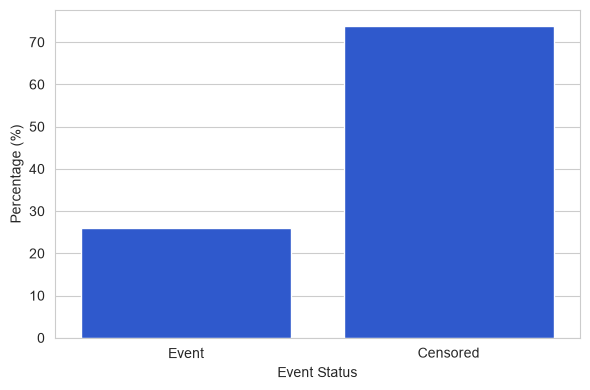

In [28]:
event_counts = merged_df["event"].value_counts().reindex([1, 0])
event_percentages = (event_counts / event_counts.sum() * 100).round(4)
print(event_percentages)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=event_counts.index.map({0: "Censored", 1: "Event"}),
    y=event_percentages.values,
    ax=ax,
    color="#154DE6"
)
ax.set_xlabel("Event Status")
ax.set_ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

count      69.000000
mean     1579.420290
std       817.706394
min        76.000000
25%       974.000000
50%      1558.000000
75%      2067.000000
max      2982.000000
Name: time, dtype: float64


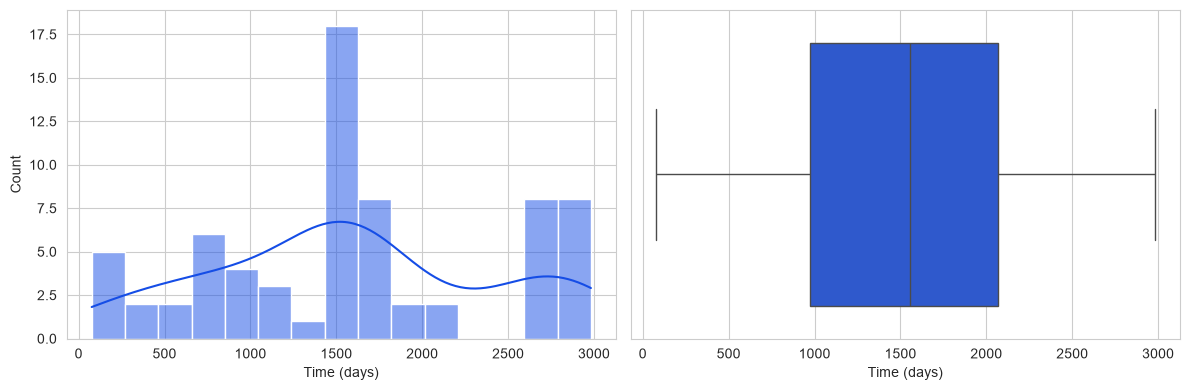

In [29]:
time_described = merged_df["time"].describe()
print(time_described)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(merged_df["time"], bins=15, kde=True, ax=ax1, color="#154DE6")
ax1.set_xlabel("Time (days)")
ax1.set_ylabel("Count")

sns.boxplot(x=merged_df["time"], ax=ax2, color="#154DE6")
ax2.set_xlabel("Time (days)")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

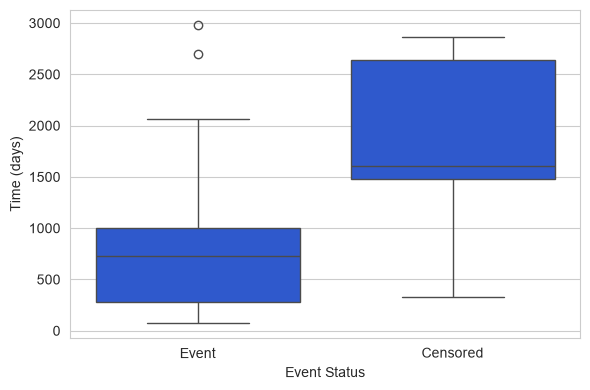

In [30]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(
    x=merged_df["event"].map({0: "Censored", 1: "Event"}),
    y=merged_df["time"],
    order=["Event", "Censored"],
    ax=ax,
    color="#154DE6"
)
ax.set_xlabel("Event Status")
ax.set_ylabel("Time (days)")
plt.tight_layout()
plt.show()

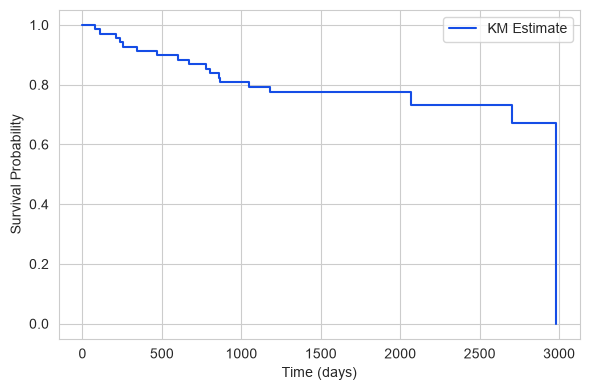

In [31]:
fig, ax = plt.subplots(figsize=(6, 4))

kmf.fit(merged_df["time"], merged_df["event"], label="KM Estimate")
kmf.plot_survival_function(ax=ax, color="#154DE6", ci_show=False)

ax.set_xlabel("Time (days)")
ax.set_ylabel("Survival Probability")
ax.get_legend().set_title(None)
plt.tight_layout()
plt.show()

## Clinical

gender
1    37.6812
0    62.3188
Name: count, dtype: float64


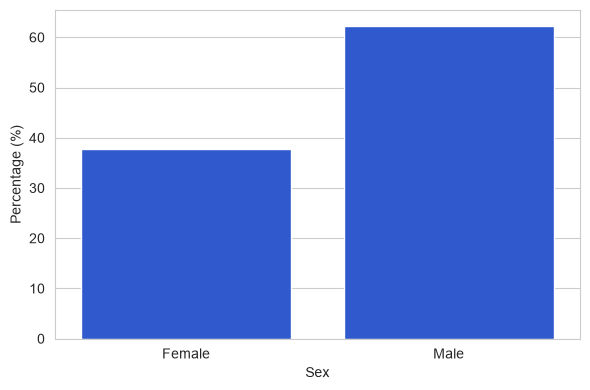

In [32]:
gender_counts = merged_df["gender"].value_counts().reindex([1, 0])
gender_percentages = (gender_counts / gender_counts.sum() * 100).round(4)
print(gender_percentages)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=gender_counts.index.map({0: "Male", 1: "Female"}),
    y=gender_percentages.values,
    ax=ax,
    color="#154DE6"
)
ax.set_xlabel("Sex")
ax.set_ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

count    69.000000
mean     40.492754
std      10.558831
min      21.000000
25%      32.000000
50%      40.000000
75%      45.000000
max      69.000000
Name: age, dtype: float64


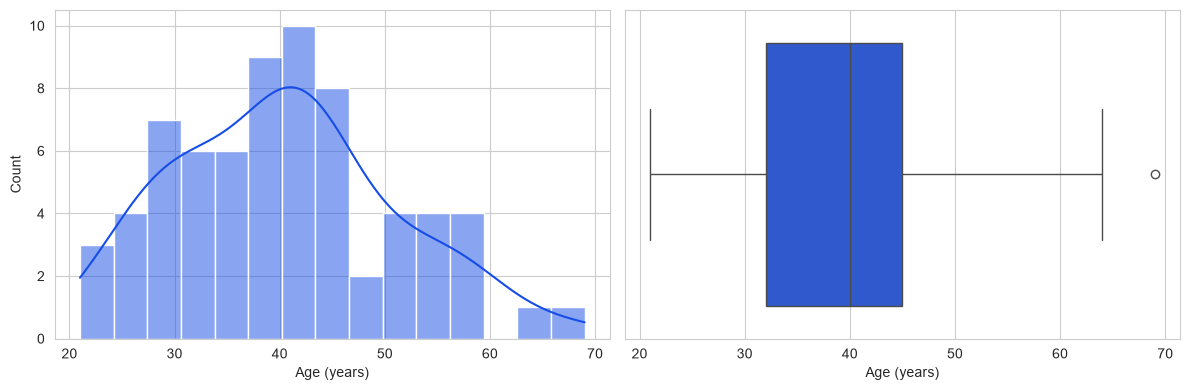

In [33]:
age_described = merged_df["age"].describe()
print(age_described)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(merged_df["age"], bins=15, kde=True, ax=ax1, color="#154DE6")
ax1.set_xlabel("Age (years)")
ax1.set_ylabel("Count")

sns.boxplot(x=merged_df["age"], ax=ax2, color="#154DE6")
ax2.set_xlabel("Age (years)")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

## Somatic Mutation

In [34]:
merged_mutation_df = merged_df[mutation_final.columns]
sparsity = ((merged_mutation_df == 0).sum().sum() / merged_mutation_df.size)
print("Sparsity:", sparsity)

Sparsity: 0.8173913043478261


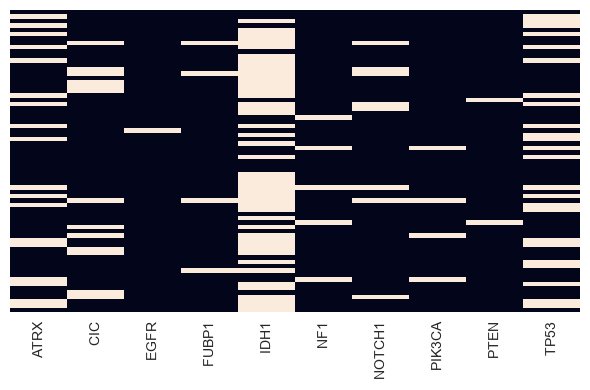

In [35]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(merged_mutation_df.rename(columns=lambda c: c.replace('_mut', '').upper()),
            cbar=False, yticklabels=False, ax=ax)
ax.set_ylabel(None)
plt.tight_layout()
plt.show()

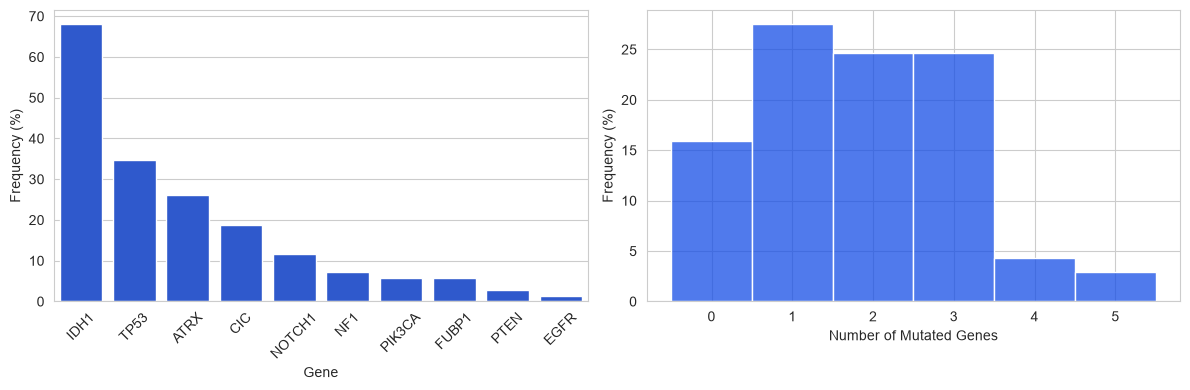

In [36]:
mutation_freq = (merged_mutation_df.mean().sort_values(ascending=False) * 100)
mutation_freq.index = mutation_freq.index.str.replace('_mut', '').str.upper()
mutation_burden = merged_mutation_df.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=mutation_freq.index, y=mutation_freq.values, color="#154DE6", ax=axes[0])
axes[0].set_xlabel("Gene")
axes[0].set_ylabel("Frequency (%)")
axes[0].tick_params(axis='x', rotation=45)

sns.histplot(mutation_burden, discrete=True, color="#154DE6", stat="percent", ax=axes[1])
axes[1].set_xlabel("Number of Mutated Genes")
axes[1].set_ylabel("Frequency (%)")
axes[1].set_xticks(range(int(mutation_burden.max()) + 1))

plt.tight_layout()
plt.show()

## Gene Expression

In [37]:
merged_expression_df = merged_df[expression_final.columns]

### Original

In [38]:
original_expression_df = merged_df[expression_original.columns]

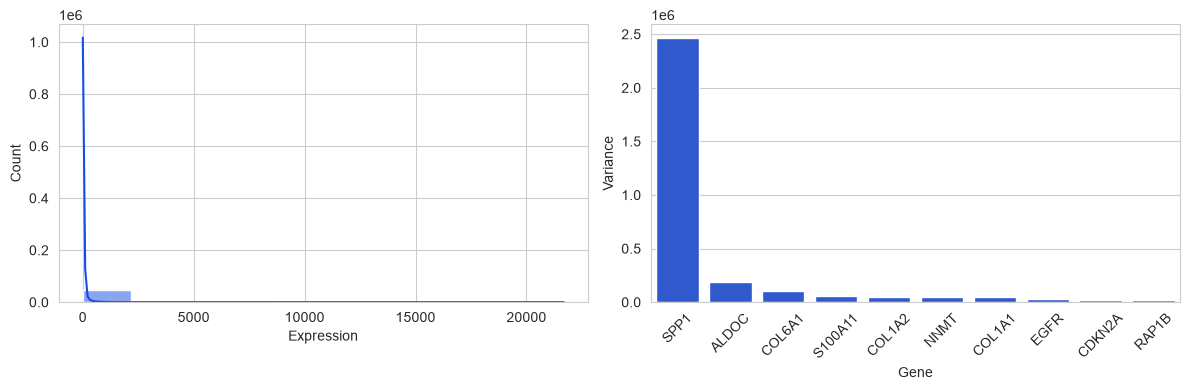

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(expression_original.values.flatten(), bins=10, kde=True, color="#154DE6", ax=axes[0])
axes[0].set_xlabel("Expression")
axes[0].set_ylabel("Count")

top10_var = expression_original.var().sort_values(ascending=False).head(10)
top10_var.index = top10_var.index.str.replace('_exp', '')
sns.barplot(x=top10_var.index, y=top10_var.values, color="#154DE6", ax=axes[1])
axes[1].set_ylabel("Variance")
axes[1].set_xlabel("Gene")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Log-transformed

In [40]:
merged_expression_df = merged_df[expression_final.columns]

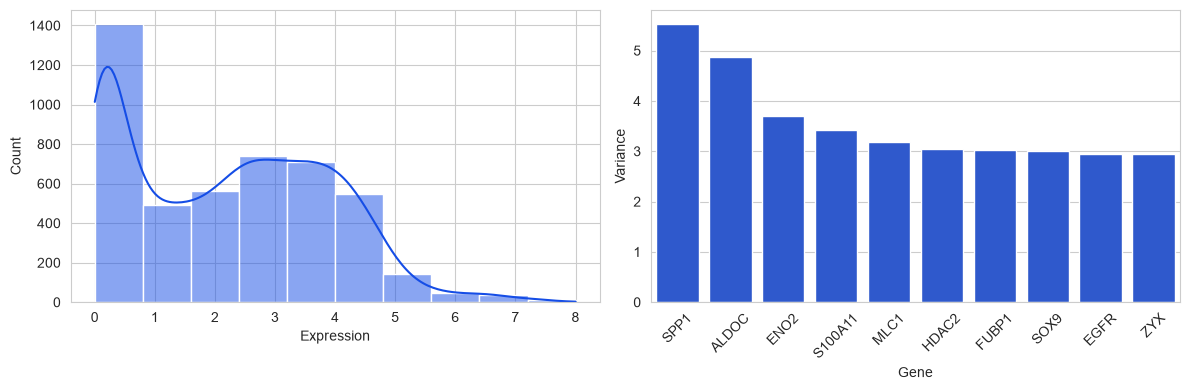

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(merged_expression_df.values.flatten(), bins=10, kde=True, color="#154DE6", ax=axes[0])
axes[0].set_xlabel("Expression")
axes[0].set_ylabel("Count")

top10_var = merged_expression_df.var().sort_values(ascending=False).head(10)
top10_var.index = top10_var.index.str.replace('_exp', '')
sns.barplot(x=top10_var.index, y=top10_var.values, color="#154DE6", ax=axes[1])
axes[1].set_ylabel("Variance")
axes[1].set_xlabel("Gene")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Dimensionality Reduction

In [42]:
dimred_merged_df = merged_df.copy()

## Somatic Mutation

In [43]:
tcga_dir = r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg"

tcga_dimred_cols = pd.read_csv(os.path.join(tcga_dir, "dimred_merged_df.csv"), nrows=0).columns
lgg_trio_mutations = [c for c in tcga_dimred_cols if c.endswith("_mut")]
print(f"Mutations kept (from TCGA): {lgg_trio_mutations}")

not_lgg_trio = [col for col in merged_mutation_df.columns if col not in lgg_trio_mutations]
not_lgg_trio_present = [c for c in not_lgg_trio if c in dimred_merged_df.columns]
dimred_merged_df.drop(columns=not_lgg_trio_present, inplace=True)

Mutations kept (from TCGA): ['ATRX_mut', 'IDH1_mut', 'TP53_mut']


## Gene Expression

In [44]:
_, tcga_coef_df, _ = joblib.load(os.path.join(tcga_dir, "global_enet_result.pkl"))
tcga_gene_weights = tcga_coef_df.set_index("feature")["coef"]
tcga_score_scaler = joblib.load(os.path.join(tcga_dir, "tcga_score_scaler.pkl"))
score_cols = list(tcga_score_scaler.feature_names_in_)
print(f"Pathway scores kept (from TCGA): {score_cols}")

Pathway scores kept (from TCGA): ['farg_score_exp', 'classical_score_exp', 'hypoxia_score_exp', 'mesenchymal_score_exp', 'g2m_score_exp']


In [45]:
g2m_genes         = ["AURKB_exp", "RPA2_exp", "MCM5_exp", "CDC45_exp", "MCM6_exp"]
pi3k_mtor_genes   = ['MAPK1_exp', 'MAPK8_exp', 'MAP3K7_exp', 'MAP2K6_exp', 'MAPK9_exp']
hypoxia_genes     = ['ALDOC_exp', 'ALDOB_exp', 'ENO2_exp', 'ENO3_exp', 'PFKP_exp']
emt_genes         = ['COL1A2_exp', 'COL1A1_exp', 'COL5A1_exp', 'COL3A1_exp', 'COL4A2_exp']
mesenchymal_genes = ['ARPC1B_exp', 'S100A11_exp', 'CTSC_exp', 'GLIPR1_exp', 'NNMT_exp']
proneural_genes   = ['RAB33A_exp', 'HDAC2_exp', 'MYT1_exp', 'MTSS1_exp']
classical_genes   = ['PTPRA_exp', 'ELOVL2_exp', 'MLC1_exp', 'SOX9_exp', 'ARNTL_exp']
farg_genes        = ['RAP1B_exp', 'VAV3_exp', 'ZYX_exp', 'COL5A2_exp', 'SPP1_exp',
                     'COL6A1_exp', 'ITGA5_exp', 'SHC1_exp']

In [46]:
pathway_gene_map = {
    "G2M Pathway":          g2m_genes,
    "PI3K mTOR Pathway":    pi3k_mtor_genes,
    "Hypoxia Pathway":      hypoxia_genes,
    "EMT Pathway":          emt_genes,
    "Mesenchymal Pathway":  mesenchymal_genes,
    "Proneural Pathway":    proneural_genes,
    "Classical Pathway":    classical_genes,
    "FARG Pathway":         farg_genes,
}

pathway_features = {
    'farg_score_exp':          'FARG Pathway',
    'classical_score_exp':     'Classical Pathway',
    'hypoxia_score_exp':       'Hypoxia Pathway',
    'emt_score_exp':           'EMT Pathway',
    'mesenchymal_score_exp':   'Mesenchymal Pathway',
    'g2m_score_exp':           'G2M Pathway',
    'pi3k_akt_mtor_score_exp': 'PI3K mTOR Pathway',
    'proneural_score_exp':     'Proneural Pathway',
}

In [47]:
def score_pathway(df, genes, weights):
    needed = [g for g in genes if weights.get(g, 0) != 0]
    missing = [g for g in needed if g not in df.columns]
    if missing:
        raise KeyError(f"Genes with non-zero TCGA weight missing from CGGA: {missing}")
    if not needed:
        return pd.Series(0.0, index=df.index)
    return df[needed].apply(zscore).multiply(weights.loc[needed].values, axis=1).sum(axis=1)

for score_col in score_cols:
    genes = pathway_gene_map[pathway_features[score_col]]
    dimred_merged_df[score_col] = score_pathway(dimred_merged_df, genes, tcga_gene_weights)

In [48]:
expr_cols = [c for c in dimred_merged_df.columns if c.endswith("_exp") and c not in score_cols]
dimred_merged_df.drop(columns=expr_cols, inplace=True)
dimred_merged_df[score_cols] = tcga_score_scaler.transform(dimred_merged_df[score_cols])
dimred_merged_df.head(5)

,event,time,gender,age,ATRX_mut,IDH1_mut,TP53_mut,farg_score_exp,classical_score_exp,hypoxia_score_exp,mesenchymal_score_exp,g2m_score_exp
patient_id,,,,,,,,,,,,
CGGA_1226,1,670.0,1,33.0,0,0,0,0.476126,0.750799,-2.174428,0.637601,-0.577054
CGGA_1232,1,2067.0,0,39.0,1,0,1,0.897044,0.390297,0.247853,0.794606,0.923914
CGGA_1303,0,2861.0,1,45.0,0,1,1,-1.938606,-1.790442,1.504536,-1.610967,-1.330609
CGGA_1305,1,2702.0,0,43.0,1,0,1,0.769344,-0.121436,0.494587,0.527555,0.679244
CGGA_1317,0,2864.0,0,45.0,0,1,0,-1.952500,-1.850753,1.806941,-1.633231,-1.380160


# Prognostic Model

In [49]:
PROGNOSTIC_FULL_COHORT = True  # True: all patients with expression data; False: only those with mutation data

if PROGNOSTIC_FULL_COHORT:
    prog_df = pd.concat([clinical_final, expression_final], axis=1, join='inner')
    prog_df = prog_df.join(mutation_final[lgg_trio_mutations], how='left')

    for score_col in score_cols:
        genes = pathway_gene_map[pathway_features[score_col]]
        prog_df[score_col] = score_pathway(prog_df, genes, tcga_gene_weights)
    prog_df[score_cols] = tcga_score_scaler.transform(prog_df[score_cols])
    prog_expression_df = prog_df[expression_final.columns]
else:
    prog_df = dimred_merged_df.copy()
    prog_expression_df = merged_expression_df

n_mut = int(prog_df[lgg_trio_mutations].notna().all(axis=1).sum())
print(f"Prognostic validation cohort: {len(prog_df)} patients, {int(prog_df['event'].sum())} events "
      f"({n_mut} with mutation data)")

Prognostic validation cohort: 265 patients, 98 events (69 with mutation data)


In [50]:
cohort_clin = clinical_693.set_index("CGGA_ID").reindex(prog_df.index)
n = len(prog_df)
print(f"Patients: {n}")
print(f"Deaths: {int(prog_df['event'].sum())} ({prog_df['event'].mean():.1%})")
print(f"Age: mean {prog_df['age'].mean():.1f} (SD {prog_df['age'].std():.1f}), median {prog_df['age'].median():.1f} years")
print(f"Female: {int(prog_df['gender'].sum())} ({prog_df['gender'].mean():.1%})")

kmf_os = KaplanMeierFitter().fit(prog_df["time"], prog_df["event"])
os_ci = median_survival_times(kmf_os.confidence_interval_)
fmt = lambda v: "NR" if np.isinf(v) else f"{v:.0f}"
print(f"Median OS: {fmt(kmf_os.median_survival_time_)} days "
      f"(95% CI {fmt(os_ci.iloc[0, 0])}-{fmt(os_ci.iloc[0, 1])})")
kmf_fu = KaplanMeierFitter().fit(prog_df["time"], 1 - prog_df["event"])
print(f"Median follow-up (reverse KM): {kmf_fu.median_survival_time_:.0f} days")
for label, s in zip(["1-year", "3-year", "5-year"], kmf_os.survival_function_at_times([365, 1095, 1825]).values):
    print(f"{label} survival: {s:.1%}")

idh = cohort_clin["IDH_mutation_status"].str.strip()
idh_known = idh.dropna()
print(f"IDH-mutant: {int((idh_known == 'Mutant').sum())}/{len(idh_known)} with known status "
      f"({(idh_known == 'Mutant').mean():.1%}); unknown: {int(idh.isna().sum())}")
print("Grade:", cohort_clin["Grade"].str.strip().value_counts().to_dict())

Patients: 265
Deaths: 98 (37.0%)
Age: mean 40.5 (SD 10.1), median 40.0 years
Female: 117 (44.2%)
Median OS: 3107 days (95% CI 2702-NR)
Median follow-up (reverse KM): 2311 days
1-year survival: 93.9%
3-year survival: 77.9%
5-year survival: 67.3%
IDH-mutant: 175/235 with known status (74.5%); unknown: 30
Grade: {'WHO III': 139, 'WHO II': 126}


## IDH Status and Age

In [51]:
idh_status = clinical_693.set_index("CGGA_ID")["IDH_mutation_status"].str.strip()
idh_df = prog_df[["time", "event", "age"]].copy()
idh_df["IDH1_mut"] = idh_status.reindex(idh_df.index).map({"Mutant": 1, "Wildtype": 0})
idh_df = idh_df.dropna(subset=["IDH1_mut"])

print(f"Patients with known IDH status: {len(idh_df)}/{len(prog_df)}")
print(f"IDH-mutant: {int(idh_df['IDH1_mut'].sum())}/{len(idh_df)} ({idh_df['IDH1_mut'].mean():.0%})")
print("Median age by IDH status:")
print(idh_df.groupby("IDH1_mut")["age"].median().rename({0: "IDH-wildtype", 1: "IDH-mutant"}).to_string())
print()

for cols in (["age"], ["IDH1_mut"], ["age", "IDH1_mut"]):
    cph_idh = CoxPHFitter().fit(idh_df[cols + ["time", "event"]], "time", "event")
    print(f"Cox model {cols}: C-index = {cph_idh.concordance_index_:.3f}")
    print(cph_idh.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3).to_string())
    print()

Patients with known IDH status: 235/265
IDH-mutant: 175/235 (74%)
Median age by IDH status:
IDH1_mut
IDH-wildtype    39.5
IDH-mutant      40.0

Cox model ['age']: C-index = 0.519
           exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%     p
covariate                                                           
age            1.004                0.984                1.026  0.68

Cox model ['IDH1_mut']: C-index = 0.664
           exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%    p
covariate                                                          
IDH1_mut       0.255                0.167                0.391  0.0

Cox model ['age', 'IDH1_mut']: C-index = 0.675
           exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                            
age            1.003                0.984                1.023  0.741
IDH1_mut       0.256                0.167                0.391  0.000



## Feature Selection

In [52]:
with open(os.path.join(tcga_dir, "cph_multi.pkl"), "rb") as f:
    tcga_cph_multi = pickle.load(f)

clinical_features = {'age': 'Age', 'gender': 'Sex'}
mutation_features = {m: m.replace('_mut', '') for m in lgg_trio_mutations}
all_features = {**clinical_features, **mutation_features,
                **{c: pathway_features[c] for c in score_cols}}

tcga_summary = tcga_cph_multi.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
sig = tcga_summary[tcga_summary['p'] < 0.05]
sig_pathways = [f for f in sig.index if f in score_cols]
final_features = ["age"] + sig_pathways

print("Significant in the TCGA multivariable Cox model (pre-specified for CGGA):")
print(sig.rename(index=all_features).round(3).to_string())

Significant in the TCGA multivariable Cox model (pre-specified for CGGA):
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%     p
covariate                                                                   
Age                    1.071                1.049                1.093  0.00
Classical Pathway      1.685                1.299                2.185  0.00
Hypoxia Pathway        1.339                1.013                1.771  0.04


In [53]:
tcga_dimred_df = pd.read_csv(os.path.join(tcga_dir, "dimred_merged_df.csv"))

def fit_tcga_model(features):
    model = CoxPHFitter()
    model.fit(tcga_dimred_df[features + ["time", "event"]], duration_col="time", event_col="event")
    return model

tcga_cph = fit_tcga_model(final_features)
tcga_median_pi = tcga_cph.predict_partial_hazard(tcga_dimred_df[final_features]).median()

print(f"TCGA prognostic model ({', '.join(all_features.get(f, f) for f in final_features)}):")
print(tcga_cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
      .rename(index=all_features).round(3).to_string())
print(f"\nTCGA median PI (risk-group cut-off): {tcga_median_pi:.4f}")

TCGA prognostic model (Age, Classical Pathway, Hypoxia Pathway):
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%     p
covariate                                                                   
Age                    1.066                1.047                1.086  0.00
Classical Pathway      1.944                1.559                2.425  0.00
Hypoxia Pathway        1.408                1.086                1.824  0.01

TCGA median PI (risk-group cut-off): 0.8382


In [54]:
df_multi = prog_df[["time", "event"] + final_features].copy()
cph_multi = CoxPHFitter()
cph_multi.fit(df_multi, duration_col="time", event_col="event")
cph_multi.print_summary()

cgga_summary = cph_multi.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
tcga_model_summary = tcga_cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]

for f in final_features:
    t, c = tcga_model_summary.loc[f], cgga_summary.loc[f]
    print(f"{all_features.get(f, f)}: "
          f"TCGA HR={t['exp(coef)']:.2f} ({t['exp(coef) lower 95%']:.2f}-{t['exp(coef) upper 95%']:.2f}), p={t['p']:.3f} | "
          f"CGGA HR={c['exp(coef)']:.2f} ({c['exp(coef) lower 95%']:.2f}-{c['exp(coef) upper 95%']:.2f}), p={c['p']:.3f}")

<lifelines.CoxPHFitter: fitted with 265 total observations, 167 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 265
number of events observed = 98
   partial log-likelihood = -493.82
         time fit was run = 2026-10-26 14:33:50 UTC

---
                     coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                            
age                  0.01      1.01      0.01           -0.02            0.03                0.98                1.03
classical_score_exp  0.44      1.55      0.15            0.14            0.73                1.16                2.08
hypoxia_score_exp    0.43      1.53      0.17            0.09            0.76                1.10                2.14

                     cmp to    z      p  -log2(p)
covariate                                        
age                    0.00 0.50   0.62      0.69
classical_score_exp    0.00 2.93 <0.005      8.18
hypoxia_score_exp      0.00 2.50   0.01      6.35
---
Concordance = 0.62
Partial AIC = 993.64
log-likelihood ratio test = 9.98 on 3 df
-log2(p) of ll-ratio test = 5.74

Age: TCGA HR=1.07 (1.05-1.09), p=0.000 | CGGA HR=1.01 (0.98-1.03), p=0.620
Classical Pathway: TCGA HR=1.94 (1.56-2.42), p=0.000 | CGGA HR=1.55 (1.16-2.08), p=0.003
Hypoxia Pathway: TCGA HR=1.41 (1.09-1.82), p=0.010 | CGGA HR=1.53 (1.10-2.14), p=0.012


In [55]:
report_labels = {
    "age": "Age (per year)",
    "pi3k_akt_mtor_score_exp": "PI3K/AKT/mTOR", "emt_score_exp": "EMT",
    "hypoxia_score_exp": "Hypoxia", "g2m_score_exp": "G2/M checkpoint",
    "farg_score_exp": "FARG", "classical_score_exp": "Classical",
    "mesenchymal_score_exp": "Mesenchymal", "proneural_score_exp": "Proneural",
}

In [56]:
def plot_forest(features, cohorts, title=None):
    """Forest plot with an HR (95% CI) and p table. cohorts = [(name, summary, colour, marker), ...],
    where summary is a lifelines summary indexed by feature. Bold values: p < 0.05."""
    from matplotlib.lines import Line2D
    from matplotlib.ticker import NullLocator
    ink, muted, grid = "#222222", "#6b6b6b", "#ececec"
    n_c = len(cohorts)
    offsets = [0.0] if n_c == 1 else list(np.linspace(-0.2, 0.2, n_c))
    labels = [report_labels.get(f, f) for f in features]

    fig, (ax, ax_t) = plt.subplots(
        1, 2, sharey=True, figsize=(9, max(2.8, len(features) * (0.3 * n_c + 0.12) + 1.0)),
        gridspec_kw={"width_ratios": [3, 2], "wspace": 0.03})

    lo = min(s.loc[features, "exp(coef) lower 95%"].min() for _, s, _, _ in cohorts)
    hi = max(s.loc[features, "exp(coef) upper 95%"].max() for _, s, _, _ in cohorts)
    x_lo, x_hi = min(lo * 0.9, 0.8), max(hi * 1.1, 1.25)

    for k, (name, s, colour, marker) in enumerate(cohorts):
        for i, f in enumerate(features):
            r, y = s.loc[f], i + offsets[k]
            weight = "bold" if r["p"] < 0.05 else "normal"
            ax.plot([r["exp(coef) lower 95%"], r["exp(coef) upper 95%"]], [y, y],
                    color=colour, lw=2, solid_capstyle="round", zorder=2)
            ax.scatter(r["exp(coef)"], y, s=60, marker=marker, zorder=3, linewidths=1.5,
                       edgecolors="white", facecolors=colour)
            if n_c > 1:
                ax_t.scatter(0.0, y, s=28, marker=marker, linewidths=1.4,
                             edgecolors="white", facecolors=colour)
            ci = f"{r['exp(coef)']:.2f} ({r['exp(coef) lower 95%']:.2f}\u2013{r['exp(coef) upper 95%']:.2f})"
            ax_t.text(0.06 if n_c > 1 else 0.0, y, ci, va="center", fontsize=10, color=ink, fontweight=weight)
            ax_t.text(0.8, y, "<0.001" if r["p"] < 0.001 else f"{r['p']:.3f}", va="center",
                      fontsize=10, color=ink, fontweight=weight)

    for a in (ax, ax_t):
        for i in range(len(features) - 1):
            a.axhline(i + 0.5, color=grid, lw=0.8, zorder=0)
    ax_t.text(0.06 if n_c > 1 else 0.0, -0.75, "HR (95% CI)", fontsize=10, color=muted, fontweight="bold", va="center")
    ax_t.text(0.8, -0.75, "p", fontsize=10, color=muted, fontweight="bold", va="center", fontstyle="italic")
    ax_t.set_xlim(-0.05, 1.05)
    ax_t.axis("off")

    ax.set_xscale("log")
    ticks = [t for t in [0.25, 0.33, 0.5, 0.67, 1, 1.5, 2, 3, 4] if x_lo <= t <= x_hi]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(x_lo, x_hi)
    for t in ticks:
        if t != 1:
            ax.axvline(t, color=grid, lw=0.8, zorder=0)
    ax.axvline(1, color="#9a9a9a", lw=1, ls="--", zorder=1)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#bdbdbd")
    ax.set_yticks(range(len(features)))
    ax.set_yticklabels(labels, color=ink, fontsize=11)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors=muted, labelsize=10)
    ax.set_ylim(len(features) - 0.5, -1.1)
    ax.set_xlabel("Hazard ratio (log scale)", color=muted, fontsize=10)

    if n_c > 1:
        handles = [Line2D([0], [0], marker=m, color=c, lw=2, markersize=7, markerfacecolor=c)
                   for _, _, c, m in cohorts]
        ax.legend(handles, [nm for nm, _, _, _ in cohorts], loc="upper left", ncol=n_c,
                  frameon=False, fontsize=10, bbox_to_anchor=(0, 1.02))
    plt.tight_layout()
    plt.show()

C:\Users\abbyn\AppData\Local\Temp\ipykernel_21732\1538720033.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


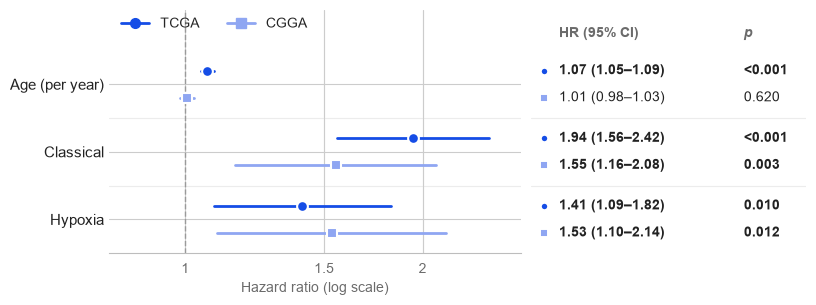

In [57]:
plot_forest(final_features,
            [("TCGA", tcga_model_summary, "#154DE6", "o"), ("CGGA", cgga_summary, "#8FA6F2", "s")])

### Adjustment for Established Markers

In [58]:
clin = clinical_693.set_index("CGGA_ID")
adj_df = prog_df[["time", "event", "age"] + sig_pathways].copy()
adj_df["IDH1_mut"] = clin["IDH_mutation_status"].str.strip().reindex(adj_df.index).map({"Mutant": 1, "Wildtype": 0})
adj_df["grade_III"] = clin["Grade"].str.strip().reindex(adj_df.index).map({"WHO II": 0, "WHO III": 1})
adj_df["codel_1p19q"] = clin["1p19q_codeletion_status"].str.strip().reindex(adj_df.index).map({"Codel": 1, "Non-codel": 0})
adj_df = adj_df.dropna()
print(f"Patients with IDH, grade and 1p19q available: {len(adj_df)}/{len(prog_df)}")

adj_labels = {**all_features, "IDH1_mut": "IDH mutant", "grade_III": "Grade III", "codel_1p19q": "1p19q codeleted"}
for label, cols in [
    ("Unadjusted",                       ["age"] + sig_pathways),
    ("Adjusted for IDH + grade",         ["age"] + sig_pathways + ["IDH1_mut", "grade_III"]),
    ("Adjusted for IDH + grade + 1p19q", ["age"] + sig_pathways + ["IDH1_mut", "grade_III", "codel_1p19q"]),
]:
    cph_adj = CoxPHFitter().fit(adj_df[cols + ["time", "event"]], "time", "event")
    print()
    print(f"{label} (n={len(adj_df)}): C-index = {cph_adj.concordance_index_:.3f}")
    print(cph_adj.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
          .rename(index=adj_labels).round(3).to_string())

Patients with IDH, grade and 1p19q available: 203/265

Unadjusted (n=203): C-index = 0.602
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                    
Age                    1.000                0.976                1.024  0.993
Classical Pathway      1.664                1.110                2.494  0.014
Hypoxia Pathway        1.253                0.886                1.772  0.203

Adjusted for IDH + grade (n=203): C-index = 0.746
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                    
Age                    0.997                0.975                1.020  0.822
Classical Pathway      1.669                1.177                2.366  0.004
Hypoxia Pathway        1.089                0.809                1.465  0.574
IDH mutant             0.249                0.155                0.400  0.000


In [59]:
from scipy.stats import chi2
for marker_label, marker_cols in [
    ("age + IDH + grade",         ["age", "IDH1_mut", "grade_III"]),
    ("age + IDH + grade + 1p19q", ["age", "IDH1_mut", "grade_III", "codel_1p19q"]),
]:
    print(f"=== Markers: {marker_label} ===")
    nested = {}
    for label, cols in [("Markers only", marker_cols), ("Markers + pathways", marker_cols + sig_pathways)]:
        nested[label] = CoxPHFitter().fit(adj_df[cols + ["time", "event"]], "time", "event")
        print(f"{label} (n={len(adj_df)}): C-index = {nested[label].concordance_index_:.3f}")
    lr_stat = 2 * (nested["Markers + pathways"].log_likelihood_ - nested["Markers only"].log_likelihood_)
    lr_df = len(sig_pathways)
    c_gain = nested["Markers + pathways"].concordance_index_ - nested["Markers only"].concordance_index_
    print(f"Likelihood-ratio test: chi2 = {lr_stat:.2f}, df = {lr_df}, p = {chi2.sf(lr_stat, lr_df):.4f}")
    print(f"C-index gain from adding the pathways: {c_gain:+.3f}")
    print()

=== Markers: age + IDH + grade ===
Markers only (n=203): C-index = 0.734
Markers + pathways (n=203): C-index = 0.746
Likelihood-ratio test: chi2 = 8.67, df = 2, p = 0.0131
C-index gain from adding the pathways: +0.012

=== Markers: age + IDH + grade + 1p19q ===
Markers only (n=203): C-index = 0.786
Markers + pathways (n=203): C-index = 0.788
Likelihood-ratio test: chi2 = 6.40, df = 2, p = 0.0408
C-index gain from adding the pathways: +0.002



In [60]:
marker_cols = {"IDH_mutation_status": "IDH", "Grade": "Grade", "1p19q_codeletion_status": "1p19q"}
missing = clin.reindex(prog_df.index)[list(marker_cols)].isna().rename(columns=marker_cols)
print("Patients missing each marker:", missing.sum().to_dict())

miss_df = prog_df[["time", "event", "age"] + sig_pathways].copy()
miss_df["complete_markers"] = miss_df.index.isin(adj_df.index)

rows = []
for complete, d in miss_df.groupby("complete_markers"):
    row = {"Group": "Complete markers" if complete else "Missing markers",
           "n": len(d), "Events": int(d["event"].sum()),
           "Median age": d["age"].median(), "Median follow-up (days)": d["time"].median()}
    for p in sig_pathways:
        f = CoxPHFitter().fit(d[["time", "event", "age", p]], "time", "event")
        r = f.summary.loc[p]
        row[f"{all_features.get(p, p)} HR (95% CI)"] = f"{r['exp(coef)']:.2f} ({r['exp(coef) lower 95%']:.2f}-{r['exp(coef) upper 95%']:.2f})"
        row[f"{all_features.get(p, p)} p"] = round(r["p"], 3)
    rows.append(row)
print(pd.DataFrame(rows).set_index("Group").to_string())

Patients missing each marker: {'IDH': 30, 'Grade': 0, '1p19q': 32}
                    n  Events  Median age  Median follow-up (days) Classical Pathway HR (95% CI)  Classical Pathway p Hypoxia Pathway HR (95% CI)  Hypoxia Pathway p
Group                                                                                                                                                               
Missing markers    62      20        41.0                   1716.5              0.97 (0.59-1.59)                0.891            1.32 (0.86-2.05)              0.207
Complete markers  203      78        40.0                   1696.0              1.56 (1.05-2.33)                0.028            1.12 (0.84-1.49)              0.436


## Performance Evaluation

### Discrimination

In [61]:
model_sets = {
    "Age only":       ["age"],
    "Pathways only":  sig_pathways,
    "Age + Pathways": final_features,
}
model_sets = {label: features for label, features in model_sets.items() if features}
tcga_models = {label: fit_tcga_model(features) for label, features in model_sets.items()}

In [62]:
def bootstrap_cindex(df, risk, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    time, event, risk = df["time"].values, df["event"].values, np.asarray(risk)
    point = concordance_index(time, -risk, event)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(df), len(df))
        boots.append(concordance_index(time[idx], -risk[idx], event[idx]))
    return point, np.percentile(boots, [2.5, 97.5])

In [63]:
cindex_results = {}
for label, features in model_sets.items():
    tcga_ci = concordance_index(tcga_dimred_df["time"],
                                -tcga_models[label].predict_partial_hazard(tcga_dimred_df[features]),
                                tcga_dimred_df["event"])
    risk = tcga_models[label].predict_partial_hazard(prog_df[features])
    point, (lo, hi) = bootstrap_cindex(prog_df, risk)
    cindex_results[label] = (point, lo, hi)
    print(f"{label}: CGGA C-index = {point:.4f} (95% CI: {lo:.4f}-{hi:.4f}) | TCGA apparent = {tcga_ci:.4f}")

Age only: CGGA C-index = 0.5230 (95% CI: 0.4572-0.5910) | TCGA apparent = 0.7793
Pathways only: CGGA C-index = 0.5772 (95% CI: 0.5099-0.6430) | TCGA apparent = 0.7462
Age + Pathways: CGGA C-index = 0.5719 (95% CI: 0.5045-0.6356) | TCGA apparent = 0.8182


In [64]:
time_points = [365, 1095, 1825]
time_labels = ["1-year", "3-year", "5-year"]

keep = [(t, l) for t, l in zip(time_points, time_labels)
        if prog_df["time"].min() < t < prog_df["time"].max()]
time_points = [t for t, _ in keep]
time_labels = [l for _, l in keep]

y_cgga_surv = np.array(
    [(bool(e), float(t)) for e, t in zip(prog_df["event"], prog_df["time"])],
    dtype=[("event", bool), ("time", float)]
)

auc_results = {}
for label, features in model_sets.items():
    risk_scores = tcga_models[label].predict_partial_hazard(prog_df[features]).values
    auc, mean_auc = cumulative_dynamic_auc(y_cgga_surv, y_cgga_surv, risk_scores, time_points)
    auc_results[label] = list(auc)
    print(f"{label}:")
    for t_label, a in zip(time_labels, auc):
        print(f"  {t_label} AUC = {a:.4f}")
    print(f"  Mean AUC = {mean_auc:.4f}\n")

Age only:
  1-year AUC = 0.4662
  3-year AUC = 0.5435
  5-year AUC = 0.5184
  Mean AUC = 0.5211

Pathways only:
  1-year AUC = 0.5798
  3-year AUC = 0.5541
  5-year AUC = 0.6105
  Mean AUC = 0.5771

Age + Pathways:
  1-year AUC = 0.5428
  3-year AUC = 0.5719
  5-year AUC = 0.5870
  Mean AUC = 0.5714



Age only: Mean AUC = 0.5291
Pathways only: Mean AUC = 0.6013
Age + Pathways: Mean AUC = 0.5980


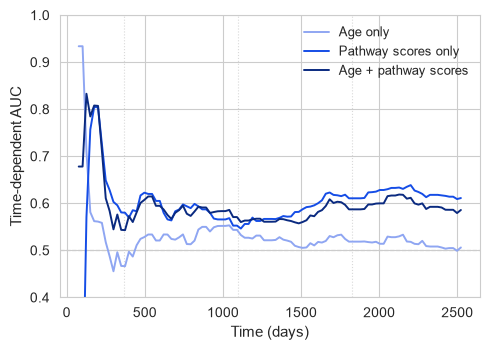

In [65]:
COLOUR, LIGHT, DARK = "#154DE6", "#8FA6F2", "#0A2A80"

event_times = prog_df.loc[prog_df["event"] == 1, "time"]
time_grid = np.linspace(event_times.min() + 1, event_times.quantile(0.90), 100)

fig, ax = plt.subplots(figsize=(5, 3.6))

for t in time_points:
    ax.axvline(t, color="#d9d9d9", lw=0.8, ls=":", zorder=0)

labels = {"Age only": "Age only", "Pathways only": "Pathway scores only",
          "Age + Pathways": "Age + pathway scores"}

for (label, features), colour in zip(model_sets.items(), [LIGHT, COLOUR, DARK]):
    risk_scores = tcga_models[label].predict_partial_hazard(prog_df[features]).values
    auc, mean_auc = cumulative_dynamic_auc(y_cgga_surv, y_cgga_surv, risk_scores, time_grid)
    ax.plot(time_grid, auc, label=labels.get(label, label), color=colour, lw=1.4)
    print(f"{label}: Mean AUC = {mean_auc:.4f}")

ax.axhline(0.5, color="grey", ls="--", lw=0.8, zorder=0)
ax.set_ylim(0.4, 1.0)
ax.set_xlabel("Time (days)", fontsize=11)
ax.set_ylabel("Time-dependent AUC", fontsize=11)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

### Calibration

1 year:
  Tertile 1: predicted = 0.930, observed = 0.910
  Tertile 2: predicted = 0.973, observed = 0.977
  Tertile 3: predicted = 0.989, observed = 0.931
3 years:
  Tertile 1: predicted = 0.665, observed = 0.708
  Tertile 2: predicted = 0.851, observed = 0.834
  Tertile 3: predicted = 0.936, observed = 0.796
5 years:
  Tertile 1: predicted = 0.483, observed = 0.587
  Tertile 2: predicted = 0.742, observed = 0.736
  Tertile 3: predicted = 0.885, observed = 0.699


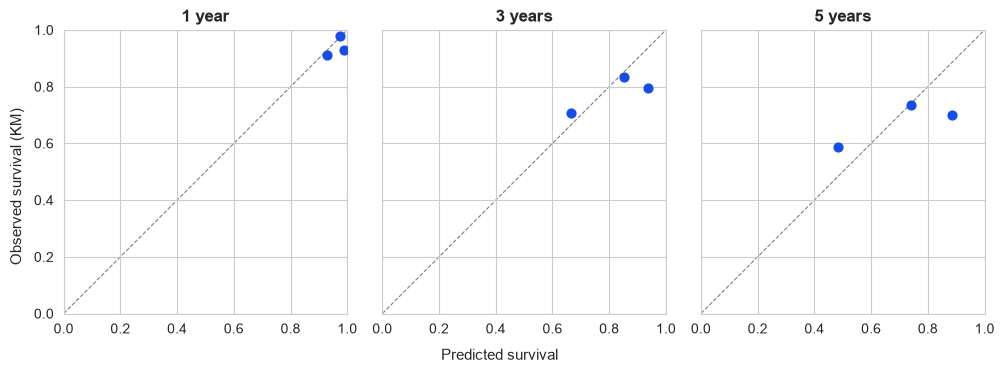

In [66]:
COLOUR = "#154DE6"
n_groups = 3
panel_titles = {182: "6 months", 365: "1 year", 730: "2 years", 1095: "3 years", 1825: "5 years"}

df_model = prog_df[final_features + ["time", "event"]].copy()

fig, axes = plt.subplots(1, len(time_points), figsize=(3.4 * len(time_points), 3.6), sharey=True)
axes = np.atleast_1d(axes)

for ax, t_eval in zip(axes, time_points):
    pred_surv = tcga_cph.predict_survival_function(df_model[final_features], times=[t_eval]).T.squeeze()
    df_cal = df_model.copy()
    df_cal["pred_surv"] = pred_surv.values
    df_cal["group"] = pd.qcut(df_cal["pred_surv"], q=n_groups, labels=False)

    observed, predicted = [], []
    for g in range(n_groups):
        grp = df_cal[df_cal["group"] == g]
        kmf = KaplanMeierFitter().fit(grp["time"], event_observed=grp["event"])
        observed.append(kmf.survival_function_at_times([t_eval]).values[0])
        predicted.append(grp["pred_surv"].mean())

    print(f"{panel_titles[t_eval]}:")
    for g, (p, o) in enumerate(zip(predicted, observed), start=1):
        print(f"  Tertile {g}: predicted = {p:.3f}, observed = {o:.3f}")

    ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=0.8, zorder=0)
    ax.scatter(predicted, observed, color=COLOUR, s=40, zorder=3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_title(panel_titles[t_eval], fontsize=12, fontweight="bold")
    ax.tick_params(labelsize=10)

fig.supxlabel("Predicted survival", fontsize=11)
fig.supylabel("Observed survival (KM)", fontsize=11)
plt.tight_layout()
plt.show()

### Risk Stratification

TCGA median PI (cut-off): 0.8382
High risk n=135, Low risk n=130
Log-rank p = 0.0602
Low Risk median survival: 3005 days (95% CI 2832-NR)
High Risk median survival: 2702 days (95% CI 2032-NR)


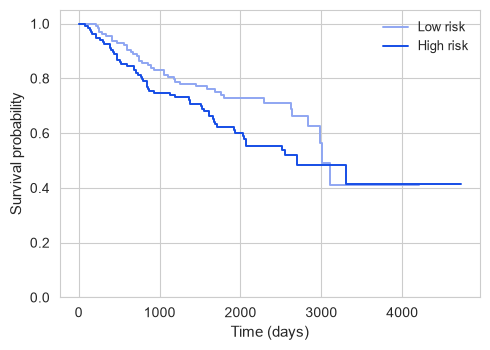

In [67]:
COLOUR, LIGHT = "#154DE6", "#8FA6F2"

df_model = prog_df[final_features + ["time", "event"]].copy()
df_model["PI"] = tcga_cph.predict_partial_hazard(df_model[final_features]).values
df_model["risk_group"] = np.where(df_model["PI"] >= tcga_median_pi, "High Risk", "Low Risk")

low = df_model[df_model["risk_group"] == "Low Risk"]
high = df_model[df_model["risk_group"] == "High Risk"]
lr = logrank_test(low["time"], high["time"], event_observed_A=low["event"], event_observed_B=high["event"])

fig, ax = plt.subplots(figsize=(5, 3.6))
kmf_objects = {}
for group, label, colour in [("Low Risk", "Low risk", LIGHT), ("High Risk", "High risk", COLOUR)]:
    mask = df_model["risk_group"] == group
    kmf = KaplanMeierFitter()
    kmf.fit(df_model.loc[mask, "time"], event_observed=df_model.loc[mask, "event"], label=label)
    kmf.plot_survival_function(ax=ax, color=colour, ci_show=False, lw=1.4)
    kmf_objects[group] = kmf

print(f"TCGA median PI (cut-off): {tcga_median_pi:.4f}")
print(f"High risk n={high.shape[0]}, Low risk n={low.shape[0]}")
print(f"Log-rank p = {lr.p_value:.4f}")
fmt = lambda v: "NR" if np.isinf(v) else f"{v:.0f}"
for group, kmf in kmf_objects.items():
    ci = median_survival_times(kmf.confidence_interval_)
    print(f"{group} median survival: {fmt(kmf.median_survival_time_)} days "
          f"(95% CI {fmt(ci.iloc[0, 0])}-{fmt(ci.iloc[0, 1])})")

ax.set_xlabel("Time (days)", fontsize=11)
ax.set_ylabel("Survival probability", fontsize=11)
ax.set_ylim(0, 1.05)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

### Group Characterisation

In [68]:
continuous_vars = final_features
var_labels = {f: all_features.get(f, f) for f in continuous_vars}

df_char = prog_df.copy()
df_char.loc[df_model.index, "PI"] = df_model["PI"]
df_char.loc[df_model.index, "risk_group"] = df_model["risk_group"]
df_char = df_char.dropna(subset=["risk_group"])

for var in continuous_vars:
    low_vals = df_char.loc[df_char["risk_group"] == "Low Risk", var].dropna()
    high_vals = df_char.loc[df_char["risk_group"] == "High Risk", var].dropna()
    stat, p = mannwhitneyu(low_vals, high_vals, alternative="two-sided")
    print(f"{var_labels[var]}:")
    print(f"  Low Risk:  median = {low_vals.median():.3f}, IQR = {low_vals.quantile(0.25):.3f}-{low_vals.quantile(0.75):.3f}")
    print(f"  High Risk: median = {high_vals.median():.3f}, IQR = {high_vals.quantile(0.25):.3f}-{high_vals.quantile(0.75):.3f}")
    print(f"  Mann-Whitney U p = {p:.4e}\n")

Age:
  Low Risk:  median = 34.000, IQR = 28.250-39.000
  High Risk: median = 45.000, IQR = 41.000-52.000
  Mann-Whitney U p = 3.8824e-26

Classical Pathway:
  Low Risk:  median = -0.219, IQR = -1.343-0.461
  High Risk: median = 0.595, IQR = 0.227-0.960
  Mann-Whitney U p = 5.5118e-12

Hypoxia Pathway:
  Low Risk:  median = -0.021, IQR = -0.606-0.473
  High Risk: median = -0.171, IQR = -0.511-0.260
  Mann-Whitney U p = 1.8513e-01



In [69]:
for mut in lgg_trio_mutations:
    if mut not in df_char.columns:
        continue
    ct = pd.crosstab(df_char["risk_group"], df_char[mut])
    if ct.shape == (2, 2):
        _, p = fisher_exact(ct)
        test = "Fisher"
    else:
        _, p, _, _ = chi2_contingency(ct)
        test = "Chi-square"
    print(f"{mut} ({test} p = {p:.4f}):")
    print(ct)
    print()

ATRX_mut (Fisher p = 0.7893):
ATRX_mut    0.0  1.0
risk_group          
High Risk    25    8
Low Risk     26   10

IDH1_mut (Fisher p = 1.0000):
IDH1_mut    0.0  1.0
risk_group          
High Risk    11   22
Low Risk     11   25

TP53_mut (Fisher p = 0.6134):
TP53_mut    0.0  1.0
risk_group          
High Risk    23   10
Low Risk     22   14



Classical Pathway by ATRX: MWU p = 0.271
Classical Pathway by IDH1: MWU p = 0.421
Classical Pathway by TP53: MWU p = 0.525

Hypoxia Pathway by ATRX: MWU p = 0.657
Hypoxia Pathway by IDH1: MWU p = 0.695
Hypoxia Pathway by TP53: MWU p = 0.664



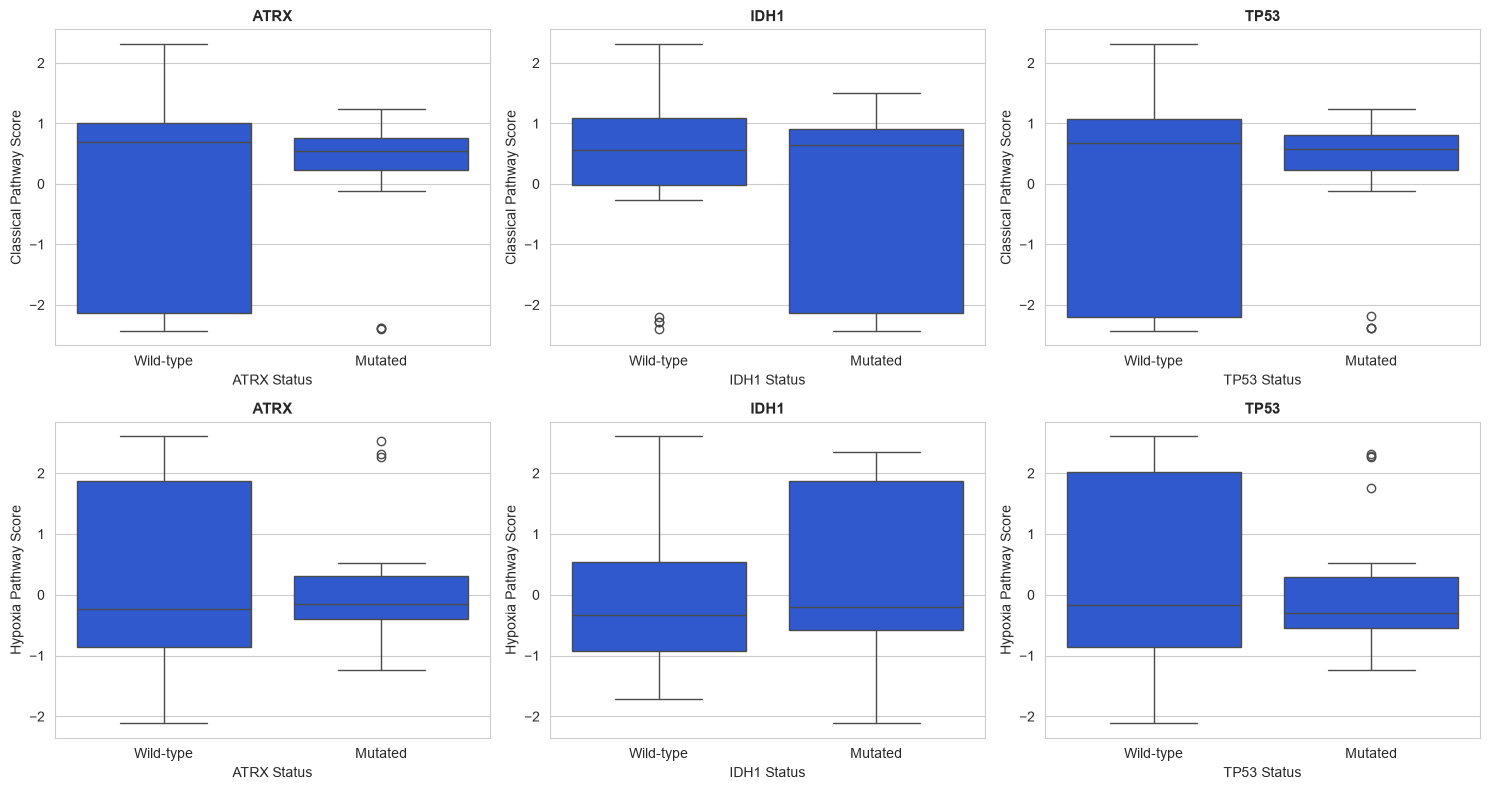

In [70]:
if len(sig_pathways) == 0:
    print("No significant pathways")
else:

    mutations = lgg_trio_mutations
    mut_labels = [m.replace("_mut", "") for m in mutations]

    n_pathways = len(sig_pathways)
    n_muts = len(mutations)

    fig, axes = plt.subplots(n_pathways, n_muts, figsize=(5 * n_muts, 4 * n_pathways))
    if n_pathways == 1:
        axes = [axes]

    for row, pathway_col in enumerate(sig_pathways):
        pathway_label = all_features.get(pathway_col, pathway_col)
        for col, (mut_col, mut_label) in enumerate(zip(mutations, mut_labels)):
            ax = axes[row][col]
            wt_vals  = prog_df.loc[prog_df[mut_col] == 0, pathway_col].dropna()
            mut_vals = prog_df.loc[prog_df[mut_col] == 1, pathway_col].dropna()

            if len(wt_vals) == 0 or len(mut_vals) == 0:
                print(f"{pathway_label} by {mut_label}: not enough patients in one group")
                ax.set_visible(False)
                continue

            _, p = mannwhitneyu(wt_vals, mut_vals, alternative="two-sided")
            p_str = "p < 0.005" if p < 0.005 else f"p = {p:.3f}"
            print(f"{pathway_label} by {mut_label}: MWU {p_str}")

            plot_df = pd.DataFrame({
                "Status": ["Wild-type"] * len(wt_vals) + ["Mutated"] * len(mut_vals),
                "Score":  pd.concat([wt_vals, mut_vals], ignore_index=True),
            })

            sns.boxplot(
                data=plot_df, x="Status", y="Score",
                hue="Status",
                order=["Wild-type", "Mutated"],
                palette={"Wild-type": "#154DE6", "Mutated": "#154DE6"},
                legend=False, ax=ax
            )
            ax.set_title(mut_label, fontsize=11, fontweight="bold")
            ax.set_xlabel(f"{mut_label} Status")
            ax.set_ylabel(f"{pathway_label} Score")

        print()

    plt.tight_layout()
    plt.show()

# Models (Original Features)

In [71]:
def cox_ph_loss(risk, time, event, eps=1e-7):
    order = torch.argsort(time, descending=True)
    risk = risk[order]
    event = event[order]
    log_risk_set = torch.logcumsumexp(risk, dim=0)
    return -((risk - log_risk_set) * event).sum() / (event.sum() + eps)

In [72]:
class DeepSurvNet(nn.Module):
    def __init__(self, input_dim, hidden_dim=16, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

In [73]:
class DeepSurv(BaseEstimator):
    def __init__(self, hidden_dim=16, dropout=0.4, weight_decay=1e-3, lr=1e-3, n_epochs=100, random_state=42):
        self.hidden_dim = hidden_dim
        self.dropout = dropout
        self.weight_decay = weight_decay
        self.lr = lr
        self.n_epochs = n_epochs
        self.random_state = random_state

    def fit(self, X, y_surv):
        torch.manual_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        time = y_surv["time"].astype(np.float32)
        event = y_surv["event"].astype(np.float32)

        self.scaler_ = StandardScaler()
        X_scaled = self.scaler_.fit_transform(X)

        X_t = torch.tensor(X_scaled, dtype=torch.float32)
        time_t = torch.tensor(time, dtype=torch.float32)
        event_t = torch.tensor(event, dtype=torch.float32)

        self.model_ = DeepSurvNet(X_t.shape[1], self.hidden_dim, self.dropout)
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)

        self.model_.train()
        self.loss_history_ = []

        for _ in range(self.n_epochs):
            optimizer.zero_grad()
            risk = self.model_(X_t)
            loss = cox_ph_loss(risk, time_t, event_t)
            loss.backward()
            optimizer.step()
            self.loss_history_.append(loss.item())
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        X_scaled = self.scaler_.transform(X)
        X_t = torch.tensor(X_scaled, dtype=torch.float32)
        self.model_.eval()
        with torch.no_grad():
            risk = self.model_(X_t).numpy()
        return risk

    def score(self, X, y_surv):
        risk = self.predict(X)
        c_index = concordance_index_censored(
            y_surv["event"].astype(bool), y_surv["time"], risk
        )[0]
        return c_index

In [74]:
model_dir = Path(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg")

results_final_logreg        = joblib.load(model_dir / "logreg.joblib")
results_final_cph           = joblib.load(model_dir / "cph.joblib")
results_final_rsf           = joblib.load(model_dir / "rsf.joblib")
results_final_gbm           = joblib.load(model_dir / "gbm.joblib")
results_final_ann           = joblib.load(model_dir / "ann.joblib")
dimred_results_final_logreg = joblib.load(model_dir / "dimred_logreg.joblib")
dimred_results_final_cph    = joblib.load(model_dir / "dimred_cph.joblib")
dimred_results_final_rsf    = joblib.load(model_dir / "dimred_rsf.joblib")
dimred_results_final_gbm    = joblib.load(model_dir / "dimred_gbm.joblib")
dimred_results_final_ann    = joblib.load(model_dir / "dimred_ann.joblib")

results_cv_logreg       = joblib.load(model_dir / "cv_logreg.joblib")
results_cv_cph          = joblib.load(model_dir / "cv_cph.joblib")
results_cv_rsf          = joblib.load(model_dir / "cv_rsf.joblib")
results_cv_gbm          = joblib.load(model_dir / "cv_gbm.joblib")
results_cv_ann          = joblib.load(model_dir / "cv_ann.joblib")
dimred_results_cv_logreg = joblib.load(model_dir / "dimred_cv_logreg.joblib")
dimred_results_cv_cph    = joblib.load(model_dir / "dimred_cv_cph.joblib")
dimred_results_cv_rsf    = joblib.load(model_dir / "dimred_cv_rsf.joblib")
dimred_results_cv_gbm    = joblib.load(model_dir / "dimred_cv_gbm.joblib")
dimred_results_cv_ann    = joblib.load(model_dir / "dimred_cv_ann.joblib")

## Statistical Models

### Logistic Regression

In [75]:
assert merged_df.index.equals(merged_mutation_df.index)
assert merged_df.index.equals(merged_expression_df.index)

In [76]:
tcga_expr = pd.read_csv(model_dir / "merged_df.csv")
shared_genes = [g for g in merged_expression_df.columns if g in tcga_expr.columns]
cgga_expr = merged_expression_df[shared_genes]
cgga_z = (cgga_expr - cgga_expr.mean()) / cgga_expr.std(ddof=0)
cgga_z = cgga_z.fillna(0)
harmonised_expression_df = cgga_z * tcga_expr[shared_genes].std(ddof=0) + tcga_expr[shared_genes].mean()
print(f"Harmonised {len(shared_genes)}/{merged_expression_df.shape[1]} genes to the TCGA scale")

y = merged_df["event"]

clinical_log = merged_df[["gender", "age"]].copy()
mutation_log = merged_mutation_df.copy()
expression_log = harmonised_expression_df.copy()

Harmonised 68/68 genes to the TCGA scale


In [77]:
model_1_log = clinical_log
model_2_log = pd.concat([clinical_log, mutation_log], axis=1)
model_3_log = pd.concat([clinical_log, expression_log], axis=1)
model_4_log = pd.concat([clinical_log, mutation_log, expression_log], axis=1)

In [78]:
def validate_logreg(name, X_cgga, y_cgga, tcga_results):
    model, _, _, _, scaler, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    X_val_scaled = scaler.transform(X_val)
    preds = model.predict_proba(X_val_scaled)[:, 1]
    return roc_auc_score(y_cgga, preds)

cgga_models = {"Model 1": model_1_log, "Model 2": model_2_log,
               "Model 3": model_3_log, "Model 4": model_4_log}

results_val_logreg = {}
for name, X in cgga_models.items():
    auc = validate_logreg(name, X, y, results_final_logreg)
    results_val_logreg[name] = auc
    print(f"{name}: Validation AUC = {auc:.3f}")

Model 1: Validation AUC = 0.461
Model 2: Validation AUC = 0.752
Model 3: Validation AUC = 0.540
Model 4: Validation AUC = 0.540


### Cox Proportional Hazards

In [79]:
y_surv = np.array(
    [(bool(e), float(t)) for e, t in zip(merged_df["event"], merged_df["time"])],
    dtype=[("event", bool), ("time", float)]
)

In [80]:
clinical_cph = merged_df[["gender", "age"]].copy()
mutation_cph = merged_mutation_df.copy()
expression_cph = harmonised_expression_df.copy()

In [81]:
model_1_cph = clinical_cph
model_2_cph = pd.concat([clinical_cph, mutation_cph], axis=1)
model_3_cph = pd.concat([clinical_cph, expression_cph], axis=1)
model_4_cph = pd.concat([clinical_cph, mutation_cph, expression_cph], axis=1)

In [82]:
def validate_cph(name, X_cgga, y_surv_cgga, tcga_results):
    model, _, _, _, scaler, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    X_val_scaled = scaler.transform(X_val)
    c_index = model.score(X_val_scaled, y_surv_cgga)
    return c_index

cgga_models_cph = {"Model 1": model_1_cph, "Model 2": model_2_cph,
                   "Model 3": model_3_cph, "Model 4": model_4_cph}

results_val_cph = {}
for name, X in cgga_models_cph.items():
    c = validate_cph(name, X, y_surv, results_final_cph)
    results_val_cph[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.473
Model 2: Validation C-index = 0.649
Model 3: Validation C-index = 0.546
Model 4: Validation C-index = 0.547


## Machine Learning Models

### Random Survival Forest

In [83]:
model_1_rsf = model_1_cph
model_2_rsf = model_2_cph
model_3_rsf = model_3_cph
model_4_rsf = model_4_cph

In [84]:
def validate_rsf(name, X_cgga, y_surv_cgga, tcga_results):
    model, _, _, _, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    return model.score(X_val, y_surv_cgga)

cgga_models_rsf = {"Model 1": model_1_rsf, "Model 2": model_2_rsf,
                   "Model 3": model_3_rsf, "Model 4": model_4_rsf}

results_val_rsf = {}
for name, X in cgga_models_rsf.items():
    c = validate_rsf(name, X, y_surv, results_final_rsf)
    results_val_rsf[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.469
Model 2: Validation C-index = 0.726
Model 3: Validation C-index = 0.774
Model 4: Validation C-index = 0.734


### Gradient Boosting

In [85]:
model_1_gbm = model_1_cph
model_2_gbm = model_2_cph
model_3_gbm = model_3_cph
model_4_gbm = model_4_cph

In [86]:
def validate_gbm(name, X_cgga, y_surv_cgga, tcga_results):
    model, _, _, _, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    return model.score(X_val, y_surv_cgga)

cgga_models_gbm = {"Model 1": model_1_gbm, "Model 2": model_2_gbm,
                   "Model 3": model_3_gbm, "Model 4": model_4_gbm}

results_val_gbm = {}
for name, X in cgga_models_gbm.items():
    c = validate_gbm(name, X, y_surv, results_final_gbm)
    results_val_gbm[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.538
Model 2: Validation C-index = 0.739
Model 3: Validation C-index = 0.654
Model 4: Validation C-index = 0.642


### Artificial Neural Network

In [87]:
model_1_ann = model_1_cph
model_2_ann = model_2_cph
model_3_ann = model_3_cph
model_4_ann = model_4_cph

In [88]:
def validate_ann(name, X_cgga, y_surv_cgga, tcga_results):
    model, _, _, _, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    return model.score(X_val, y_surv_cgga)

cgga_models_ann = {"Model 1": model_1_ann, "Model 2": model_2_ann,
                   "Model 3": model_3_ann, "Model 4": model_4_ann}

results_val_ann = {}
for name, X in cgga_models_ann.items():
    c = validate_ann(name, X, y_surv, results_final_ann)
    results_val_ann[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.487
Model 2: Validation C-index = 0.793
Model 3: Validation C-index = 0.640
Model 4: Validation C-index = 0.664


# Models (Reduced Features)

In [89]:
dimred_clinical_log   = dimred_merged_df[["gender", "age"]].copy()
dimred_mutation_log   = dimred_merged_df[lgg_trio_mutations].copy()
dimred_expression_log = dimred_merged_df[score_cols].copy()

dimred_model_1_log = dimred_clinical_log
dimred_model_2_log = pd.concat([dimred_clinical_log, dimred_mutation_log], axis=1)
dimred_model_3_log = pd.concat([dimred_clinical_log, dimred_expression_log], axis=1)
dimred_model_4_log = pd.concat([dimred_clinical_log, dimred_mutation_log, dimred_expression_log], axis=1)

In [90]:
cgga_dimred_models = {"Model 1": dimred_model_1_log, "Model 2": dimred_model_2_log,
                      "Model 3": dimred_model_3_log, "Model 4": dimred_model_4_log}

In [91]:
dimred_results_val_logreg = {}
for name, X in cgga_dimred_models.items():
    auc = validate_logreg(name, X, y, dimred_results_final_logreg)
    dimred_results_val_logreg[name] = auc
    print(f"{name}: Validation AUC = {auc:.3f}")

Model 1: Validation AUC = 0.461
Model 2: Validation AUC = 0.747
Model 3: Validation AUC = 0.549
Model 4: Validation AUC = 0.597


In [92]:
dimred_results_val_cph = {}
for name, X in cgga_dimred_models.items():
    c = validate_cph(name, X, y_surv, dimred_results_final_cph)
    dimred_results_val_cph[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.473
Model 2: Validation C-index = 0.647
Model 3: Validation C-index = 0.479
Model 4: Validation C-index = 0.493


In [93]:
dimred_results_val_rsf = {}
for name, X in cgga_dimred_models.items():
    c = validate_rsf(name, X, y_surv, dimred_results_final_rsf)
    dimred_results_val_rsf[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.469
Model 2: Validation C-index = 0.613
Model 3: Validation C-index = 0.530
Model 4: Validation C-index = 0.560


In [94]:
dimred_results_val_gbm = {}
for name, X in cgga_dimred_models.items():
    c = validate_gbm(name, X, y_surv, dimred_results_final_gbm)
    dimred_results_val_gbm[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.538
Model 2: Validation C-index = 0.603
Model 3: Validation C-index = 0.504
Model 4: Validation C-index = 0.569


In [95]:
dimred_results_val_ann = {}
for name, X in cgga_dimred_models.items():
    c = validate_ann(name, X, y_surv, dimred_results_final_ann)
    dimred_results_val_ann[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.487
Model 2: Validation C-index = 0.746
Model 3: Validation C-index = 0.510
Model 4: Validation C-index = 0.675


# Model and Method Evaluation

In [96]:
model_names = ["Model 1", "Model 2", "Model 3", "Model 4"]

val_rows = []
for name in model_names:
    val_rows.append({
        "Model": name, "Feature Set": "Original",
        "LogReg TCGA Test AUC":     results_cv_logreg[name][0],
        "LogReg TCGA Test AUC SD":  results_cv_logreg[name][2],
        "LogReg TCGA Train AUC":    results_cv_logreg[name][1],
        "LogReg CGGA Val AUC":      results_val_logreg[name],
        "CPH TCGA Test C-index":    results_cv_cph[name][0],
        "CPH TCGA Test C-index SD": results_cv_cph[name][2],
        "CPH TCGA Train C-index":   results_cv_cph[name][1],
        "CPH CGGA Val C-index":     results_val_cph[name],
        "RSF TCGA Test C-index":    results_cv_rsf[name][0],
        "RSF TCGA Test C-index SD": results_cv_rsf[name][2],
        "RSF TCGA Train C-index":   results_cv_rsf[name][1],
        "RSF CGGA Val C-index":     results_val_rsf[name],
        "GBM TCGA Test C-index":    results_cv_gbm[name][0],
        "GBM TCGA Test C-index SD": results_cv_gbm[name][2],
        "GBM TCGA Train C-index":   results_cv_gbm[name][1],
        "GBM CGGA Val C-index":     results_val_gbm[name],
        "ANN TCGA Test C-index":    results_cv_ann[name][0],
        "ANN TCGA Test C-index SD": results_cv_ann[name][2],
        "ANN TCGA Train C-index":   results_cv_ann[name][1],
        "ANN CGGA Val C-index":     results_val_ann[name],
    })
    val_rows.append({
        "Model": name, "Feature Set": "Reduced",
        "LogReg TCGA Test AUC":     dimred_results_cv_logreg[name][0],
        "LogReg TCGA Test AUC SD":  dimred_results_cv_logreg[name][2],
        "LogReg TCGA Train AUC":    dimred_results_cv_logreg[name][1],
        "LogReg CGGA Val AUC":      dimred_results_val_logreg[name],
        "CPH TCGA Test C-index":    dimred_results_cv_cph[name][0],
        "CPH TCGA Test C-index SD": dimred_results_cv_cph[name][2],
        "CPH TCGA Train C-index":   dimred_results_cv_cph[name][1],
        "CPH CGGA Val C-index":     dimred_results_val_cph[name],
        "RSF TCGA Test C-index":    dimred_results_cv_rsf[name][0],
        "RSF TCGA Test C-index SD": dimred_results_cv_rsf[name][2],
        "RSF TCGA Train C-index":   dimred_results_cv_rsf[name][1],
        "RSF CGGA Val C-index":     dimred_results_val_rsf[name],
        "GBM TCGA Test C-index":    dimred_results_cv_gbm[name][0],
        "GBM TCGA Test C-index SD": dimred_results_cv_gbm[name][2],
        "GBM TCGA Train C-index":   dimred_results_cv_gbm[name][1],
        "GBM CGGA Val C-index":     dimred_results_val_gbm[name],
        "ANN TCGA Test C-index":    dimred_results_cv_ann[name][0],
        "ANN TCGA Test C-index SD": dimred_results_cv_ann[name][2],
        "ANN TCGA Train C-index":   dimred_results_cv_ann[name][1],
        "ANN CGGA Val C-index":     dimred_results_val_ann[name],
    })

val_df = pd.DataFrame(val_rows).round(3)
val_df

,Model,Feature Set,LogReg TCGA Test AUC,LogReg TCGA Test AUC SD,LogReg TCGA Train AUC,LogReg CGGA Val AUC,CPH TCGA Test C-index,CPH TCGA Test C-index SD,CPH TCGA Train C-index,CPH CGGA Val C-index,...,RSF TCGA Train C-index,RSF CGGA Val C-index,GBM TCGA Test C-index,GBM TCGA Test C-index SD,GBM TCGA Train C-index,GBM CGGA Val C-index,ANN TCGA Test C-index,ANN TCGA Test C-index SD,ANN TCGA Train C-index,ANN CGGA Val C-index
0,Model 1,Original,0.644,0.071,0.652,0.461,0.786,0.053,0.780,0.473,...,0.853,0.469,0.757,0.074,0.819,0.538,0.778,0.063,0.781,0.487
1,Model 1,Reduced,0.644,0.071,0.652,0.461,0.786,0.053,0.780,0.473,...,0.853,0.469,0.757,0.074,0.819,0.538,0.778,0.063,0.781,0.487
2,Model 2,Original,0.652,0.027,0.703,0.752,0.807,0.040,0.818,0.649,...,0.862,0.726,0.832,0.028,0.889,0.739,0.763,0.047,0.791,0.793
3,Model 2,Reduced,0.677,0.030,0.696,0.747,0.795,0.039,0.802,0.647,...,0.871,0.613,0.781,0.042,0.875,0.603,0.766,0.044,0.805,0.746
4,Model 3,Original,0.738,0.022,0.783,0.540,0.855,0.023,0.881,0.546,...,0.910,0.774,0.812,0.070,0.944,0.654,0.800,0.056,0.863,0.640
5,Model 3,Reduced,0.740,0.037,0.772,0.549,0.813,0.040,0.845,0.479,...,0.898,0.530,0.827,0.044,0.879,0.504,0.820,0.049,0.841,0.510
6,Model 4,Original,0.736,0.023,0.824,0.540,0.844,0.031,0.886,0.547,...,0.902,0.734,0.822,0.046,0.947,0.642,0.806,0.049,0.878,0.664
7,Model 4,Reduced,0.741,0.025,0.778,0.597,0.804,0.045,0.841,0.493,...,0.905,0.560,0.828,0.024,0.890,0.569,0.770,0.036,0.812,0.675


# Model Export

In [97]:
val_df_lgg = val_df.copy()
val_df_lgg.to_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_lgg\val_df_lgg.csv", index=False)